# List Recoloring of Sparse Graphs

In [1]:
import networkx as nx
import random  # to generate random lists
import math
from time import perf_counter
from pathlib import Path
import heapq
import numpy as np
from itertools import combinations, product

## 1. Introduction and Preliminaries

This notebook is designed to accompany a paper (of the same title) by Daniel W. Cranston, available on arXiv at [https://arxiv.org/abs/2201.05133](https://arxiv.org/abs/2201.05133).  

A *list-assignment* $L$ for a graph $G$ gives to each vertex $v\in V(G)$ a list (set) of allowable colors $L(v)$.  And an $L$-coloring is a proper coloring $\varphi$ such that $\varphi(v)\in L(v)$ for each vertex $v$.  In this notebook (and the corresponding paper) we are given a graph $G$, a list-assignment $L$ and two $L$-colorings $\alpha,\beta$. We aim to transform $\alpha$ into $\beta$ through a sequence of single-vertex recoloring steps.  In each step we recolor a single vertex with a color in its list to get a new (proper) $L$-coloring.  Our goal is to find a path from $\alpha$ to $\beta$, and in particular to find a path that is *short*.  More precisely, we will specify some constant $C$ and guarantee (for large classes of graphs $G$ and list-assignments $L$) that as we transfrom $\alpha$ to $\beta$ no vertex is recolored more than $C$ times.  The foundation of all of our work is the following result.

**Extension Lemma**. Fix a graph $G$, a list-assignment $L$ for $G$, and $L$-colorings $\alpha$ and $\beta$. Fix a vertex
$v$ with $|L(v)| \ge d(v)+2$ and let $G' := G−v$. Fix an $L$-recoloring sequence $\sigma'$ for $G'$ transforming
$\alpha_{\upharpoonright G}$ to $\beta_{\upharpoonright G}$. If $\sigma'$ recolors $N_G(v)$ a total of $t$ times, then we can extend $\sigma'$ to an $L$-recoloring sequence for $G$ transforming $\alpha$ into $\beta$ and recoloring $v$ at most $\lceil t/(|L(v)| − d_G(v)− 1)\rceil + 1$ times.

Proving the Extension Lemma is relatively straightforward.  The proof is essentially a greedy algorithm with limited look-ahead.  But the Extension Lemma has the following easy consequence (the next result).  This notebook does not include many proofs, but the proof below is particularly enlightening, so we include it.  Before stating it, we need another definition.  A graph $G$ is *$d$-degenerate* if each non-empty subgraph $H$ of $G$ contains a vertex $v$ such that $d_H(v)\le d$.  (For example, every tree is 1-degenerate, and every planar graph is 5-degenerate.  Furthermore, every planar *triangle-free* graph is 3-degenerate.)

**Recoloring $d$-Degenerate Graphs Lemma**: Fix a $d$-degenerate $n$-vertex graph $G$ with a list assignment $L$ such that $|L(v)| \ge 2d+2$ for all $v\in V(G)$.  If $\alpha$ and $\beta$ are $L$-colorings of $G$, then we can transform (recolor) $\alpha$ to $\beta$ in at most $(d+1)n$ steps; furthermore, we can ensure that each vertex is recolored at most $d+1$ times.

**Proof**:  The (overall) bound $(d+1)n$ follows immediately from the bound $d+1$ for each vertex, so we prove that.  Our proof is by induction on $n$, the order of the graph.  If the graph has at most 1 vertex, then the result holds trivially.  So now we assume that $n\ge 2$.
Let $v$ be a vertex of degree at most $d$ in $G$ (such a vertex exists because $G$ is $d$-degenerate).  Let $G':= G-v$, and denote by $\alpha', \beta'$ the restrictions to $G'$ of $\alpha,\beta$.  By the induction hypothesis, $G'$ has a recoloring sequence from $\alpha'$ to $\beta'$ with each vertex recolored at most $d+1$ times.  Now by the Extension Lemma, we extend $\sigma'$ to a sequence $\sigma$ from $\alpha$ to $\beta$.  Each vertex except $v$ is recolored at most $d+1$ times, by hypothesis.  And the number of times vertex $v$ is recolored is at most $\lceil(d(d+1)/((2d+2)-d-1)\rceil+1 = d+1$.

Before we go any further, we write a straightforward verifier, ```verify_rseq```, to confirm that an input sequence of recoloring steps is really a valid $L$-recoloring sequence from one $L$-coloring $\alpha$ to another $\beta$.  *Verifying* a recoloring sequence (rather than *constructing* it) is easy.  We simply start at $\alpha$ and try to perform each of the specified recoloring steps in sequence.  At each step, we must check that the resulting coloring is again proper, and (of course) is again an $L$-coloring, i.e., the new color for the recolored vertex is contained in its list.  Finally, we must check that the final coloring is indeed $\beta$. By default, our verifier just returns raises an assertion error, if the sequence is invalid not.  But we can also get a bit more information with the option ```info=True```.

In [2]:
def verify_rseq(G, rseq: list, start_coloring: dict, end_coloring: dict, lists: dict, info=False):
    # most of the inputs should be clear.  But lists is a dictionary with the list (set) of allowable colors for each vertex.
    # returns silently if recoloring sequence is valid and info == False
    assert all(start_coloring[v] != start_coloring[w] for v,w in G.edges), "Starting coloring is improper."
    assert all(end_coloring[v] != end_coloring[w] for v,w in G.edges), "Ending coloring is improper."
    assert all(start_coloring[v] in lists[v] for v in G), "Starting coloring is not from lists!"
    assert all(end_coloring[v] in lists[v] for v in G), "Ending coloring is not from lists!"
    assert start_coloring.keys() >= G.nodes(), "Starting coloring leaves some vertex uncolored!"
    assert end_coloring.keys() >= G.nodes(), "Ending coloring leaves some vertex uncolored!"
    assert len(start_coloring) == len(G) and len(end_coloring) == len(G), "One or both colorings color vertices not in G!"
    
    curr_coloring = start_coloring.copy()
    for num, (v, color) in enumerate(rseq, start=1):
        assert color in lists[v], f"Cannot recolor {v} to {color} at step {num}, since {color} is not in its list: {lists[v]}."
    for num, (v, color) in enumerate(rseq, start=1):
        curr_coloring[v] = color
        for w in G.neighbors(v):
            assert curr_coloring[v] != curr_coloring[w], f"At step {num} cannot recolor {v} with {color}, since it is already used on {w}."
    assert curr_coloring == end_coloring, "Recoloring sequence does not reach the desired end coloring!"
    if info:
        print("Recoloring sequence is valid.")
        counts = {v:0 for v in G}
        for (v, color) in rseq:
            counts[v] += 1
        assert len(rseq) == sum(counts[v] for v in G)
        max_times = max(counts.values())
        min_times = min(counts.values())
        summary_info = {"max_times": max_times, "min_times": min_times, "total_times": len(rseq)}
        print(summary_info)
    return True

### 1.1 Easy example of ```verify_rseq```

As a toy example, we consider two 3-colorings of the path on 9 vertices, $P_9$.

In [3]:
path9 = nx.path_graph(9)
path9_coloring1 = {i:(i%3)+1 for i in range(9)}
path9_coloring2 = {i:3- i%3 for i in range(9)}
path9_lists = {v:{1,2,3} for v in path9}
print(f"Coloring 1: {path9_coloring1} and Coloring 2: {path9_coloring2}")

Coloring 1: {0: 1, 1: 2, 2: 3, 3: 1, 4: 2, 5: 3, 6: 1, 7: 2, 8: 3} and Coloring 2: {0: 3, 1: 2, 2: 1, 3: 3, 4: 2, 5: 1, 6: 3, 7: 2, 8: 1}


In [4]:
path9_rseq = [(0,3), (1,1), (2,2), (3,3), (0,2), (1,3), (2,1), (0,1), (1,2), (0,3), 
            (8,1), (7,3), (6,2), (5,1), (8,2), (7,1), (6,3), (8,3), (7,2), (8,1)]  

In [5]:
is_valid = verify_rseq(path9, path9_rseq, path9_coloring1, path9_coloring2, path9_lists, info=True)

Recoloring sequence is valid.
{'max_times': 4, 'min_times': 0, 'total_times': 20}


## 2. Finding a recoloring sequence

The main goal of this notebook is to **efficiently construct** the recoloring sequence that is guaranteed to exist by the proof above.
By *efficiently*, in practice we mean something with running time $O(n\log n)$.  We will not focus on running time *proofs*, but rather motivate our developments at a more intuitive level.  Given a generic $d$-degenerate input graph $G$, we have two step to implement the proof:
1. Construct a $d$-degeneracy order of $V(G)$, i.e., each vertex has at most $d$ neighbors later in the order.
2. Use the (reverse of this) order, with repeated application of the Extension Lemma, to construct the recoloring sequence.

Naively implemented, each of these steps might take quadratic time.  For (1), we might need a linear scan at each step to find a vertex of degree at most $d$.  And for (2), we might need a linear scan at each step to construct the restriction of the recoloring sequence to $N(v)$, the neighborhood of the vertex that we are re-inserting in the graph.  It is easy to implement (1) to run in linear time per vertex, so quadratic time overall, so we omit the details.  It is also straightforward to do this for (2), but as a warmup we give
some code below that does the job.

### 2.1 Naive List Implementation (yielding $O(n^2)$ running time)

In [7]:
def find_rseq(G, coloring1: dict, coloring2: dict, lists: dict, to_add_order: list, info=False):
    curr_coloring = {}
    rseq = []
    added = set()
    for v in to_add_order:
        curr_coloring, rseq = extend_rseq(curr_coloring, rseq, 
                                          v, lists[v], coloring1[v], coloring2[v], set(G.neighbors(v))&added)
        added |= {v}
    assert verify_rseq(G, rseq, coloring1, coloring2, lists, info=info)
    return rseq

In [6]:
def extend_rseq(coloring: dict, recolor_seq: list, v: int, v_colors: set, 
                   v_source: int, v_target: int, v_nbrs: set, DEBUG=False) -> tuple[dict, list]:
    def dprint(a):
        if DEBUG:
            print(a)
            
    #coloring = coloring0.copy()
    #recolor_seq = recolor_seq0.copy()
    coloring[v] = v_source
    dprint(f"v_nbrs is {v_nbrs}")
    nbrs_r_seq = [(num, vert, color) for num, (vert, color) in enumerate(recolor_seq) if vert in v_nbrs]
    dprint(nbrs_r_seq)
    curr_color = {v:coloring[v] for v in (v_nbrs | {v}) }  # dictionary that maintains colors on N[v]
    how_many = len(v_colors) - len(v_nbrs) - 1

    ext_to_v_seq = []
    for i in range(len(nbrs_r_seq)):
        num, vert, color = nbrs_r_seq[i]
        dprint(f"nbrs_r_seq[i] is {nbrs_r_seq[i]}")
        if color != curr_color[v]:
            curr_color[vert] = color
        else:
            to_avoid1 = {curr_color[w] for w in v_nbrs}
            dprint(f"to_avoid1 is {to_avoid1}.")
            to_avoid2 = {nbrs_r_seq[i+j][2] for j in range(min(how_many,len(nbrs_r_seq)-i))}
            dprint(f"to_avoid2 is {to_avoid2}.")
            allowed_colors = v_colors - (to_avoid1 | to_avoid2)
            dprint(f"allowed_colors is {allowed_colors}.")
            picked_color = next(iter(allowed_colors))
            dprint(f"picked_color is {picked_color}.")
            curr_color[v] = picked_color
            curr_color[vert] = color
            ext_to_v_seq.append((num, picked_color))

    # ext_to_v_seq ... (num, color)  # list: each step recolors v with color, just before step num in recolor_seq 
    #print(f"ext_to_v_seq is {ext_to_v_seq}")
    if (len(ext_to_v_seq) == 0 and v_target != v_source) or (len(ext_to_v_seq) >= 1 and ext_to_v_seq[-1][1] != v_target):
        ext_to_v_seq.append((len(recolor_seq), v_target))
    dprint(f"ext_to_v_seq is {ext_to_v_seq}")
    
    for i in range(len(ext_to_v_seq)-1,-1,-1):  # insert in order of decreasing index to keep indexing consistent
        dprint(f"recolor_seq is {recolor_seq}")
        dprint(f"i is {i}")
        recolor_seq.insert(ext_to_v_seq[i][0], (v, ext_to_v_seq[i][1]))
        dprint(f"recolor_seq is {recolor_seq}")
    return coloring, recolor_seq

#### 2.1.1 The Example on $P_9$ (Revisited)

Here we revisit our toy example of a path on 9 vertices, $P_9$.  Now we can use ```find_rseq``` to actually *find* the recoloring sequence that we previously only verified.

In [8]:
path9_rseq2 = find_rseq(path9, path9_coloring1, path9_coloring2, path9_lists, [4, 3, 2, 1, 0, 5, 6, 7, 8], info=True)
print(path9_rseq2)

Recoloring sequence is valid.
{'max_times': 4, 'min_times': 0, 'total_times': 20}
[(0, 3), (1, 1), (2, 2), (3, 3), (0, 2), (1, 3), (2, 1), (0, 1), (1, 2), (0, 3), (8, 1), (7, 3), (6, 2), (5, 1), (8, 2), (7, 1), (6, 3), (8, 3), (7, 2), (8, 1)]


Note that, in fact, our algorithm has found the exact sequence that we provided it above.

In [9]:
path9_rseq2 == path9_rseq

True

#### 2.1.2 Testing Bigger Graphs (where our algorithm is *too slow*)

To test ```find_rseq```, we write a few helper functions, ```build_d_degen```, ```make_lists```, and ```build_random_coloring```. These build random $d$-degenerate graphs (given $d$ and a desired order $n$), random lists (given a graph, a list size, and a pallete size), and a random coloring (given a graph and its lists).

In [10]:
def build_d_degen(n: int, d=1):
    G = nx.complete_graph(d+1)
    G.add_nodes_from(list(range(d+1,n)))
    for v in range(d+1,n):
        nbrhd = random.sample(range(v),d)
        for w in nbrhd:
            G.add_edge(v,w)
    return G

In [11]:
def make_lists(vert_set, union_size, list_size) -> dict:
    my_lists = {}
    for v in vert_set:
        my_lists[v] = set(random.sample(range(union_size), list_size))
    return my_lists

In [12]:
def build_random_coloring(G, lists, G_order = None) -> dict:
    my_colors = {}
    if G_order == None:
        G_order = list(range(len(G)))
    G_order_index = {G_order[i]:i for i in range(len(G_order))}
    for v in G_order:
        early_nbrs = {w for w in G.neighbors(v) if G_order_index[w] < G_order_index[v]}
        to_avoid = {my_colors[w] for w in early_nbrs}
        v_color = random.sample(list(lists[v]-to_avoid),1)[0]
        my_colors[v] = v_color
    return my_colors

In [13]:
n = 10_000
d = 5
G_random = build_d_degen(n,d)
G_random_lists = make_lists(G_random, 5*d, 2*(d+1))
coloring1 = build_random_coloring(G_random, G_random_lists)
coloring2 = build_random_coloring(G_random, G_random_lists)

In [14]:
G_random_rseq = find_rseq(G_random, coloring1, coloring2, G_random_lists, G_random, info=True)

Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 11019}


Running times vary with the particular random graph that we get.  But they typically exceed 15 seconds.  For a 10,000-vertex graph this is *too slow*, as we would like to be able to scale up to handle graphs 10 times that size, or larger (and we will).

The core issue here is that our naive implementation has running time $\Theta(n^2)$.  So if we scale up by a factor of 10, the running time will (roughly) increase by a factor of 100.  To overcome this issue, we **need a faster implementation**.  To be clear, we will **keep the same core algorithm**: iteratively apply the Extension Lemma to one vertex after another.  But to implement this approach more efficiently, we will need a different data structure.

## 3. Treaps with Event Dictionaries

To speed up our implementation, we will store everything in a *treap*.  A treap is a binary search tree (with events stored at internal nodes) where each node has a priority and each parent has priority at least as large as the priorities of each of its children. 
The recoloring sequence is stored implicitly in the treap and can be recovered by an in-order traversal.  The main point is that if the graph is $d$-degenerate, then we can insert a new vertex in (expected) time $d^2\log n$.  We do this $n$ times, and then at the end, we do an in-order traversal to extract the recoloring sequence.  (We don't need to have a current copy of the recoloring sequence after every insertion.)  For each vertex v, we will store pointers to the nodes of the treap when it gets updated.  The key points are as follows:

1. The expected depth of the treap will be $O(\log n)$.  This expectation is over the uniform distribution of priorities.  In particular, we assume that each of the $n!$ possible relative orders of these priorities is equally likely.
2. For each recoloring event, we can compute its "rank" (position in the recoloring sequence) in time proportional to its depth in the treap.
3. For each vertex already inserted (into the graph $G$), we store a list of its recoloring events (times that vertex was recolored, and what color it got).
4. When we insert a new vertex $v$ into $G$, we collect all of the recoloring events of its neighbors, compute the rank for each event, and sort these events into a list (ordered by their ranks).  Then we determine any needed recoloring events for $v$, create a list for these (stored with $v$), and insert each event into the treap.
5. The expensive parts of this process are (a) calculating the rank for each neighbor event $O(d(d+1)\log n)$ and (b) rebalancing the treap after we insert a recoloring event for $v$: $O(\log n)$ for one, so $O((d+1)\log n)$ in total.  (We may also need to sort the $O(d^2)$ recoloring events among the neighbors of $v$.  But that takes time $O(d^2\log d)$, which is dominated by the $O(d(d+1)\log n)$ work calculating the ranks.)

### 3.1 Implementing ```Treap```

The main work of this section is implementing the ```Treap``` class.  A version of treaps is already implemented for Python, but it does not (directly) offer the functionality we need here.  Specifically, we need to be able to maintain a pointer to an event (node in the treap) and insert a new event immediately before that event, even if that event has moved around in the treap since we inserted it.  (Since each node of the treap will be an event, we also implement the ```Event``` class.)

In [15]:
class Event:
    def __init__(self, v, color, priority):
        self.size = 1
        self.priority = priority
        self.vertex = v
        self.color = color

        self.lchild = None
        self.rchild = None
        self.parent = None

    def find_rank(self):
        curr_rank = 1
        curr_spot = self
        if self.lchild is not None:
            curr_rank += self.lchild.size
        while curr_spot.parent is not None:
            if curr_spot.parent.rchild == curr_spot:  # curr_spot is rchild of its parent
                curr_spot = curr_spot.parent
                curr_rank += 1
                if curr_spot.lchild is not None:
                    curr_rank += curr_spot.lchild.size
            else:
                curr_spot = curr_spot.parent
        
        return curr_rank

    # For in in-order traversal, we may want to just output for each event its vertex and color (which we do by default)
    # but we may also want to print the priority and/or the rank
    def print_event(self, priority=False, rank=False):
        if priority:
            if rank:
                print(f"((({self.vertex},{self.color}), priority = {self.priority}), rank = {self.find_rank()})")
            else:
                print(f"(({self.vertex},{self.color}), priority = {self.priority})")
        else:
            if rank:
                print(f"(({self.vertex},{self.color}), rank = {self.find_rank()})")
            else:
                print(f"({self.vertex},{self.color})")

# a minor helper function, so that we can handle the cases lchild = None and rchild = None in a unified way
def size(node):
    if node is None:
        return 0
    else:
        return node.size

# This class is where the bulk of the work happens.
class Treap:
    def __init__(self):
        self.root = None

    # this is how we can print the current (implicit) recoloring sequence at any point, possibly along with priorities and/or ranks
    def inorder_traversal(self, priority=False, rank=False):
    
        def inorder_rec(event):
            if event.lchild is not None:
                inorder_rec(event.lchild)
            event.print_event(priority = priority, rank = rank)
            if event.rchild is not None:
                inorder_rec(event.rchild)
    
        if self.root is not None:
            inorder_rec(self.root)

    # this is how we extract the recoloring sequence at the end
    # similar to inorder_traversal, except that we print nothing and return the whole recoloring sequence as a list
    def get_list(self):
        rseq_as_list = []
    
        def get_list_rec(event):
            nonlocal rseq_as_list
            if event.lchild is not None:
                get_list_rec(event.lchild)
            rseq_as_list.append((event.vertex, event.color))
            if event.rchild is not None:
                get_list_rec(event.rchild)
    
        if self.root is not None:
            get_list_rec(self.root)
        return rseq_as_list

    # each time that we recolor a vertex we must create an event for that recoloring, and insert that event into the treap
    def insert_event(self, event, next_event):
        # first we handle the case where the treap is empty, i.e., this is the first insertion
        if self.root is None and next_event is None:
            self.root = event
            return
        # next we handle the case where we are "appending" to the treap
        # this is a bit different than normal, because we usual give the pointer to what we insert "right before"
        elif next_event is None:
            curr = self.root
            while curr.rchild is not None:
                curr.size += 1
                curr = curr.rchild
            curr.size += 1
            curr.rchild = event
            event.parent = curr

            # if we appended, then now we need to restore the heap invariant (make priorities satisfy the required inequality)
            curr = event
            while (curr.parent is not None) and (curr.priority > curr.parent.priority):
                self.rotate_up_left(curr)
            return
            
        # if we reach here (and do not return above), then we are in a "normal" insertion case
        # either we insert as a left child of next_event (if no left child exists)
        if next_event.lchild is None:
            next_event.lchild = event
            event.parent = next_event
        # or we insert as the rightmost descendant of a left child (of next_event) if that left child exists
        else:
            curr_event = next_event.lchild
            while curr_event.rchild is not None:
                curr_event = curr_event.rchild
            curr_event.rchild = event
            event.parent = curr_event

        # now we must increase size by 1 for each ancestor on a path to the root
        path_to_root = event
        while path_to_root.parent is not None:
            path_to_root = path_to_root.parent
            path_to_root.size += 1

        # and finally, we restore the invariant for priorities  (ensure that it is still a heap)
        while (event.parent is not None) and (event.priority > event.parent.priority):
            if event.parent.rchild == event:  # event is right child of parent
                self.rotate_up_left(event)
            else:  # event is left child of parent
                self.rotate_up_right(event)
            

    # the way that we main the heap invariant is by rotating events with higher priorities up toward the root
    # either we rotate_up_right or we rotate_up_left
    def rotate_up_right(self, event):
        # assumes parent.lchild == event
        parent_parent = event.parent.parent
        parent = event.parent
        root_to_shift = event.rchild

        parent.lchild = root_to_shift

        if root_to_shift is not None:
            root_to_shift.parent = parent
        parent.parent = event
        event.rchild = parent
     
        event.parent = parent_parent
        if parent_parent is None:
            self.root = event
        else:
            if parent_parent.rchild == parent:
                parent_parent.rchild = event
            else:  # parent_parent.lchild == parent:
                parent_parent.lchild = event
        parent.size = 1 + size(parent.lchild) + size(parent.rchild)
        event.size = 1 + size(event.lchild) + size(event.rchild)

    def rotate_up_left(self, event):
        # assumes parent.rchild == event
        parent_parent = event.parent.parent
        parent = event.parent
        root_to_shift = event.lchild

        parent.rchild = root_to_shift

        if root_to_shift is not None:
            root_to_shift.parent = parent
        parent.parent = event 
        event.lchild = parent
        
        event.parent = parent_parent
        if parent_parent is None:
            self.root = event
        else:
            if parent_parent.rchild == parent:
                parent_parent.rchild = event
            else:  # parent_parent.lchild == parent:
                parent_parent.lchild = event
        parent.size = 1 + size(parent.lchild) + size(parent.rchild)
        event.size = 1 + size(event.lchild) + size(event.rchild)

    def check_invariants(self):  # Mainly just for testing/debugging
        def check_r(node, parent):
            if node is None:
                return 0
    
            assert node.parent is parent
            assert node.lchild is None or node.priority >= node.lchild.priority
            assert node.rchild is None or node.priority >= node.rchild.priority
            assert node.parent is None or node.priority <= node.parent.priority
            assert 1+check_r(node.lchild, node) + check_r(node.rchild, node) == node.size
            return node.size
    
        assert self.root is None or self.root.parent is None
        return check_r(self.root, None)


### 3.2 Testing ```Treap```

This section is just to test the implementation of treap.  We take a list of length 20, pick a random permutation of $\{1,\ldots,20\}$ and insert into the treap the elements of the list in order as prescribed by the permutation.  Regardless of the order in which we insert them into the treap, at the end we should get back (via our in-order traversal) the list we started with.  More strongly, at each step along the way the sublist implicit in the treap should match the sublist induced by the elements we have already inserted.

In [16]:
def sub_list(indices0: set) -> list:  # has access to global variables perm and my_list
    indices = sorted(indices0)
    #print(f"indices is {indices}")
    temp_list = []
    for i in indices:
        #print(f"perm is {perm}.")
        #print(f"my_list is {my_list}")
        #print(f"i is {i} and my_list[perm[i]-1] is {my_list[i-1]}")
        temp_list += [my_list[i-1]]
    return temp_list

my_list = [(0,3), (1,1), (2,2), (3,3), (0,2), (1,3), (2,1), (0,1), (1,2), (0,3), 
            (8,1), (7,3), (6,2), (5,1), (8,2), (7,1), (6,3), (8,3), (7,2), (8,1)]  
n = len(my_list)

def check_insertion_perm(perm):    
    my_treap = Treap()
    inserted = set()
    #perm = random.sample(range(1,21), 20)
    #print(perm)
    my_events = [None for _ in range(n)]
    for i in range(n):
        vert, color = my_list[perm[i]-1]
        next_event = None
        for j in range(n-1, perm[i]-1, -1):  # find next_event
            if my_events[j] is not None:
                next_event = my_events[j]
        temp = Event(vert, color, random.random())
        my_treap.insert_event(temp, next_event)
        inserted |= {perm[i]}
        
        my_events[perm[i]-1] = temp
        assert my_treap.check_invariants() == len(inserted)

        for k in range(n):
            if my_events[k] is not None:
                temp = my_events[k]
                easy_rank = sum(1 for j in inserted if j <= k+1)
                assert temp.find_rank() == easy_rank, "Ranks don't match!"   
        
        rseq_curr = my_treap.get_list()
        my_list_curr = sub_list(inserted)
        #print(f"i is {i} and {my_list_curr} == {sub_list(inserted)} is {my_list_curr == sub_list(inserted)}")
        assert rseq_curr == my_list_curr, f"rseq_curr is {rseq_curr} but my_list_curr is {my_list_curr} and inserted is {inserted}."

for _ in range(10000):
    perm = random.sample(range(1,n+1), n)
    check_insertion_perm(perm)

And here are a few more adversarial insertion permutations.

In [17]:
perm1 = [1+i for i in range(20)]
perms = [] 
for i in range(20):
    temp_perm = perm1[:i]+list(reversed(perm1[i:]))
    perms.append(temp_perm)
    perms.append(list(reversed(temp_perm)))

for perm in perms:
    check_insertion_perm(perm)

### 3.3 Using ```Treap``` to find recoloring sequences

Now we come to the actual algorithm ```find_rseq_treap``` to construct a recoloring sequence.  Mainly, this is a wrapper for the function ```extend_rseq_treap```, which does all of the work.  We don't pass much from the wrapper function, just the vertex and its list; most of the data we need is just inherited from the wrapper.  At the end, we verify that our recoloring sequence is indeed valid, before returning it.

In [18]:
def find_rseq_treap(G, coloring1: dict, coloring2: dict, lists: dict, to_add_order: list, info=False):
    coloring_events = {v:[] for v in G}
    assert set(to_add_order) == set(G.nodes()) and len(to_add_order) == len(G), "to_add_order must include each vertex of G exactly once."
    recolor_seq = Treap()
    added_verts = set()

    def extend_rseq_treap(v: int, v_colors: set):
        nonlocal G, recolor_seq, coloring1, coloring2, coloring_events
    
        v_source, v_target = coloring1[v], coloring2[v]
        nbrs_recolor_seq = []
        v_nbrs = set(G.neighbors(v)) & added_verts
        for w in v_nbrs:
            w_events = [(event.find_rank(), event.vertex, event.color, event) for event in coloring_events[w]]
            nbrs_recolor_seq += w_events
        nbrs_recolor_seq.sort()
        curr_color = {w:coloring1[w] for w in (v_nbrs | {v}) }  # dictionary that maintains colors on N[v]
        how_many = len(v_colors) - len(v_nbrs) - 1
    
        ext_to_v_seq = []
        for i in range(len(nbrs_recolor_seq)):
            num, vert, color, event = nbrs_recolor_seq[i]
            if color != curr_color[v]:
                curr_color[vert] = color
            else:
                to_avoid1 = {curr_color[w] for w in v_nbrs}
                to_avoid2 = {nbrs_recolor_seq[i+j][2] for j in range(min(how_many,len(nbrs_recolor_seq)-i))}
                allowed_colors = v_colors - (to_avoid1 | to_avoid2)
                picked_color = next(iter(allowed_colors))
                curr_color[v] = picked_color
                curr_color[vert] = color
                ext_to_v_seq.append((event, picked_color))
    
        # ext_to_v_seq ... (event, color)  # list: each step recolors v with color, just before event in recolor_seq 
        if (len(ext_to_v_seq) == 0 and v_target != v_source) or (len(ext_to_v_seq) >= 1 and ext_to_v_seq[-1][1] != v_target):
            ext_to_v_seq.append((None, v_target))
        
        for next_event, color in ext_to_v_seq:
            priority = random.random()
            new_event = Event(v,color,priority)
            recolor_seq.insert_event(new_event, next_event) 
            coloring_events[v] += [new_event]
    
    for v in to_add_order:
        extend_rseq_treap(v, lists[v])
        added_verts |= {v}
    
    rseq_as_list = recolor_seq.get_list()
    verify_rseq(G, rseq_as_list, coloring1, coloring2, lists, info=info)
    return rseq_as_list

#### 3.3.1 The helper functions to test ```find_rseq_treap```

The main takeaway, from the 2 cells below, is that ```find_rseq_treap``` is *fast*.  For a 10,000-vertex 5-degenerate graph, it is typically well under a second.  Remember that G_random (with its associated lists and colorings) is the same graph that took over 15 seconds to process by ```find_rseq```.

In [19]:
G_random_rseq = find_rseq_treap(G_random, coloring1, coloring2, G_random_lists, G_random, info=False)

In [20]:
check = verify_rseq(G_random, G_random_rseq, coloring1, coloring2, G_random_lists, info=True)

Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 11019}


We proved the following result near the start of the notebook, but for easy reference, we repeat it here.

**Recoloring $d$-Degenerate Graphs Lemma**: Fix a $d$-degenerate $n$-vertex graph $G$ with a list assignment $L$ such that $|L(v)| \ge 2d+2$ for all $v\in V(G)$.  If $\alpha$ and $\beta$ are $L$-colorings of $G$, then we can transform (recolor) $\alpha$ to $\beta$ in at most $(d+1)n$ steps; furthermore, we can ensure that each vertex is recolored at most $d+1$ times.

In practice, we typically still get very good performance (lengths of recoloring sequences) even with somewhat smaller lists.  We are guaranteed to find a recoloring sequence whenenver all lists have size at least $d+2$, but the length of that sequence might be superlinear.
The next two sections can be viewed as special cases when we can improve on the list size required above and still get recoloring sequences where each vertex is recolored a bounded number of times.

Below is the code to regenerate a new (larger) instance of ```G_random```.  The 2nd argument to G_random_lists specifies the size of the *palette* (set from which each list is drawn) and the 3rd specifies the size of each list.

Even for bigger and somewhat denser graphs, time is really not an issue.

In [21]:
n = 100_000
d = 15
G_random = build_d_degen(n,d)
G_random_lists = make_lists(G_random, 2*(d+1),2*(d+1))
coloring1 = build_random_coloring(G_random, G_random_lists)
coloring2 = build_random_coloring(G_random, G_random_lists)

In [45]:
G_random_rseq = find_rseq_treap(G_random, coloring1, coloring2, G_random_lists, G_random, info=True)

Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 15231}


We can also allow non-constant lists.  In theory, these lists could make things harder for us.  But in practice, they typically make our job easier.

In [46]:
G_random = build_d_degen(n,d)
G_random_lists = make_lists(G_random, 5*d,2*(d+1))
coloring1 = build_random_coloring(G_random, G_random_lists)
coloring2 = build_random_coloring(G_random, G_random_lists)

In [47]:
G_random_rseq = find_rseq_treap(G_random, coloring1, coloring2, G_random_lists, G_random, info=True)

Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 15128}


## 4. Lists of Size 6

The *average degree* of a graph is the average of its vertex degrees.  The *maximum average degree*, $\mbox{mad}(G)$, of a graph $G$ is the maximum of the average degree of a subgraph $H$, over all subgraphs $H$.  Graphs of bounded maximum average degree are widely studied families of sparse graphs.  In the paper, we proved the following.

**Theorem 2**: If $\mbox{mad}(G)<17/5$ and $L$ consists of lists of size 6 and $\alpha,\beta$ are $L$-colorings, then $G$ admits an $L$-recoloring sequence from $\alpha$ to $\beta$ that recolors each vertex at most 12 times.

Rather than focus on constructing graphs $G$ with $\mbox{mad}(G) < 17/5$, we work with a larger class of graphs for which we know that our recoloring algorithm will succeed.  In the proof of Theorem 2, we showed that every graph $G$ with $\mbox{mad}(G)<17/5$ admits one of 3 "reducibile configurations", and we showed how to handle the existence of each of the configurations, using "reducibility steps".  So to generate graphs for which the algorithm will work, we simply reverse these 3 reducibility steps.

In [23]:
def gen_graph_6lists(n: int):
    #G = nx.Graph()
    assert n >= 4, "Ask for more vertices"  # otherwise, one of the cases below gets more finicky
    G = nx.cycle_graph(4)
    two_verts = [0,1,2,3]
    num_verts = 4

    def remove_random_2():  # returns a random 2-vertex
        nonlocal two_verts
        assert len(two_verts) > 0, "Can't remove from an empty set!"
        i = random.randrange(len(two_verts))
        v = two_verts[i]
        two_verts[i] = two_verts[-1]
        two_verts.pop()
        return v

    def add_2(v):  # adds a new 2-vertex v to the "pile"
        nonlocal two_verts
        two_verts.append(v)
        
    
    while num_verts < n:
        v = num_verts
        num_verts += 1
        G.add_node(v)
        #cut_off = random.random()
        
        if len(two_verts) >= 4:  # and cut_off > .1:
            for _ in range(4):
                w = remove_random_2()
                G.add_edge(v,w)
        elif len(two_verts) >= 2:  # and cut_off < .9:
            to_avoid = []
            for _ in range(2):
                w = remove_random_2()
                to_avoid.append(w)
                G.add_edge(v,w)
            while True:
                w = random.randrange(num_verts-1)
                if w not in to_avoid and w not in two_verts:  # be careful here  (two_vertices has at most 1 vertex)
                    G.add_edge(v,w)
                    break
        else:
            to_avoid = two_verts.copy()
            add_2(v)
            for i in range(2):
                while True:
                    w = random.randrange(num_verts-1)
                    if w not in to_avoid:
                        G.add_edge(v,w)
                        to_avoid.append(w)
                        break
                        
    return G

In [24]:
for i in range(1,101):
    n = 10000
    G_random = gen_graph_6lists(n)
    G_random_lists = make_lists(G_random, 6,6)  # increase first 6 for more diverse lists
    coloring1 = build_random_coloring(G_random, G_random_lists)
    coloring2 = build_random_coloring(G_random, G_random_lists)

    G_random_rseq = find_rseq_treap(G_random, coloring1, coloring2, G_random_lists, G_random, info=False)
    if i%10 == 0:
        print(f"Successfully finished graph number {i}.")

Successfully finished graph number 10.
Successfully finished graph number 20.
Successfully finished graph number 30.
Successfully finished graph number 40.
Successfully finished graph number 50.
Successfully finished graph number 60.
Successfully finished graph number 70.
Successfully finished graph number 80.
Successfully finished graph number 90.
Successfully finished graph number 100.


It is worth noting that our graph constructor ```gen_graph_6lists``` gives us the vertex order needed for ```find_rseq_treap```; it is simply increasing order.  However, we might get a graph for which our recoloring algorithm will work, but without the appropriate vertex order.  In this case, we need to *find* the order.  The basic idea is that at each step we find one of the 3 reducible configurations and delete it.  But doing this naively could lead to linearly many *linear* scans, resulting in quadratic time.

The handy trick we need is a "candidate list".  We keep a running list of places to look for reducible configurations.  At the start, we run a preprocessing phase, to initially populate this list, which takes time $O(n)$.  But the key idea is that at each step after this we can quickly extract from this list a reducible configuration.  We also need to *repopulate* the candidate list as we "erode" our graph.  The point is that any new candidates must be nearby the just-deleted candidate, so we can find them in constant time.  It is possible that we may extract a candidate (reducible configuration) from the candidates list with all of its vertices already deleted from $G$ (a so-called "stale" candidate).  In that case, we just discard the candidate and proceed to the next candidate.  So any time that we find a good candidate, we could take a long time ($\Theta(n)$).  But only linearly many candidates ever enter the candidate list.  So the *amortized* time per candidate is $O(1)$.

### 4.1 Finding Orders for Lists of Size 6

4.1.1 Testing the Orders for Lists of Size 6

In [25]:
def find_order_for_6lists(G0) -> list:
    G = G0.copy()
    order = []

    DEBUG = False #True
    
    def dprint(a):
        if DEBUG == True:
            print(a)
    
    def is_candidate(v) -> bool:
        if G.degree(v) <= 2:
            return True
        elif G.degree(v) == 3:
            nbr_degrees = sorted([G.degree(w) for w in G.neighbors(v)])
            if nbr_degrees[0] <= 3 and nbr_degrees[1] <= 3:
                return True
        elif G.degree(v) == 4 and all(G.degree(w) <= 3 for w in G.neighbors(v)):
            return True
        return False

    candidates = [v for v in G if is_candidate(v)]  # initially populate the candidates list
    dprint(f"candidates is {candidates}")

    while candidates != []:
        v = candidates.pop()
        if G.has_node(v):
            dprint(f"About to delete vertex {v}")
            G_nbrs = list(G.neighbors(v))
            G.remove_node(v)
            dprint(f"Removed {v} from G: opposite of {G.has_node(v)}.")
            for w in G_nbrs:
                dprint(f"Considering neighbor vertex {w}.")
                if is_candidate(w):
                    candidates.append(w)
                    dprint(f"Adding {w} to candidates.")
                if G.degree(w) <= 3:
                    for x in G.neighbors(w):
                        if is_candidate(x):
                            candidates.append(x)
                            dprint(f"Adding {x} to candidates.")
            order.append(v)
            dprint(f"order is {order}")
            

    #print(f"order is {order}")
    dprint(f"order has size {len(order)} but G has order {len(G0.nodes)}")
    assert set(order) == set(G0.nodes()), "Didn't get all of the vertices into the order!"
    return list(reversed(order))
            

In [26]:
n = 13000
G_random = gen_graph_6lists(n)

Now we want to test our ability to find an order, and not just use the (implicit) order in which the graph was constructed.  For this, we just randomly permute the vertex names.  Now we know that some order exists, but our algorithm has no idea what it is.

In [27]:
perm = list(G_random.nodes())
random.shuffle(perm)
mapping = dict(zip(G_random.nodes(),perm))
H = nx.relabel_nodes(G_random, mapping)

In [28]:
H_order = find_order_for_6lists(H)

In [29]:
H_lists = make_lists(H,6,6)
coloring1 = build_random_coloring(H, H_lists, H_order)
coloring2 = build_random_coloring(H, H_lists, H_order)

In [30]:
H_rseq = find_rseq_treap(H, coloring1, coloring2, H_lists, H_order, info=True)

Recoloring sequence is valid.
{'max_times': 4, 'min_times': 0, 'total_times': 16387}


## 5. Triangle-free Planar Graphs

Theorem 1 of the paper is as follows.

**Theorem 1**: Let $G$ be a planar triangle-free graph. Fix a 7-assignment $L$ for $G$ and $L$-colorings
$\alpha$ and $\beta$. There exists an $L$-recoloring sequence that transforms $\alpha$ into $\beta$ such that each vertex
is recolored at most 30 times.

The purpose of this section is to implement this result.  To construct the desired recoloring sequence, given $G$, $L$, $\alpha$, and $\beta$ as above, we will again rely on ```find_rseq_treap```.  So the main work of this section is to take as input a triangle-free planar graph $G$ and construct an approriate vertex order to pass to ```find_rseq_treap```.  In principal, our approach will be similar to that in the previous section for lists of size 6.  But we have a few key differences: 

1. now our reducibility arguments (from the proof of Theorem 1) require deleting multiple vertices in a single step; and
2. now our types of reducible configurations are more numerous, and we have weaker bounds on their diameter.

It is also worth remarking about planarity.  Each of our reducible configurations containing a 4-cycle is guaranteed to appear with that 4-cycle as the boundary of a 4-face.  This property is useful for the proof (of unavoidability), but is not needed for the reducibility step.  Thus, we will not enforce this requirement when finding reducible configurations.  This relaxation allows us to avoid maintaining a planar embedding throughout the process, which simplifies the implementation.

In [31]:
def find_order_for_7lists(G0, check=True) -> list:
    # check = False allows to skip the checks for planarity and triangle-freeness, which are a bit time-consuming
    
    TIMING = False #True
    def tprint(*args):  # for timing investigations
        if TIMING == True:
            print(*args)
            
    t = perf_counter()
    G = G0.copy()
    tprint("Copy:", perf_counter() - t)
    if check == True:
        is_planar, embedding = nx.check_planarity(G)
        assert is_planar, "Graph must be planar!"
        assert all(set(G.neighbors(v)) & set(G.neighbors(w)) == set() for v,w in G.edges()), "Graph must be triangle-free!"
    order = []

    DEBUG = False #True
    
    def dprint(a):
        if DEBUG == True:
            print(a)

    def is_3_or_4_with_3(v) -> list:  # helper function for finding good paths in is_candidate below
        # if v is a 3^--vertex, return [v]; if v is a 4-vertex with a 3^--nbr w, return [w, v]; else return []
        if G.degree(v) <= 3:
            return [v]
        elif G.degree(v) == 4:
            nbr_degrees = sorted([(G.degree(w), w) for w in G.neighbors(v)])
            if nbr_degrees[0][0] <= 3:
                return [nbr_degrees[0][1], v]
        return []
    
    def is_candidate(v) -> list:
        # returns a reducible config containing v, if such a config exists
        # for each v, only need at most one config containing it, since that config will lead to v being deleted
        #
        # KEY POINT: reducible configs are "subgraph closed" This means that if some vertices of a reducible config are missing
        # (because they were already deleted), we can still reduce the remaining subgraph of the reducible config
        # specifically, we still append to the order the sublist for the config induced by whichever vertices are still present
        #
        # we want v to go at the *end* of the list we return, since ultimately we will reverse the vertex order that we are growing
        #
        # if vertex v does not appear in any reducible configuration, we simply return a list of length 0
        
        if G.degree(v) <= 2:
            return [v]
        if G.degree(v) == 3:
            nbr_degrees = sorted([(G.degree(w), w) for w in G.neighbors(v)])
            if nbr_degrees[0][0] <= 3:
                return [nbr_degrees[0][1], v]
            return []
        elif G.degree(v) == 4:
            # captures the case that v is the "middle" of 3-4-3, 3-4-4-3, 3-4-4-4-3, or opposite the 3 on a 3-4-4-4 4-cycle
            # don't need to worry about unexpected "wrap-around", since we already checked that G is triangle-free
            for w,x in combinations(G.neighbors(v), 2):
                w_list = is_3_or_4_with_3(w)
                x_list = is_3_or_4_with_3(x)
                if w_list != [] and x_list != []:
                    if len(w_list) == 2 and len(x_list) == 2:
                        if w_list[0] == x_list[0]:
                            del w_list[0]
                    return w_list+x_list+[v]
            return []
            
        elif G.degree(v) == 5:
            nbr_degrees = sorted([(G.degree(w), w) for w in G.neighbors(v)])
            # case that v has >= 3 neighbors, each of degree <= 3
            if nbr_degrees[0][0] <= 3 and nbr_degrees[1][0] <= 3 and nbr_degrees[2][0] <= 3:
                return [nbr_degrees[0][1], nbr_degrees[1][1], nbr_degrees[2][1], v]
        
            # still need to handle 4-cycles rooted at 5-vertices with extra 3-neighbors  (we do that below)
            nbrs_3m = {w for w in G.neighbors(v) if G.degree(w) <= 3}
            nbrs_4m = {w for w in G.neighbors(v) if G.degree(w) <= 4}
            for w in nbrs_3m:
                for x,y in combinations(nbrs_4m - {w}, 2):
                    if G.degree(x) > G.degree(y):
                        x,y = y,x
                    #if G.degree(x) <= 4 and G.degree(y) <= 4:
                    for z in set(G.neighbors(x)) & set(G.neighbors(y)):
                        if G.degree(z) <= 3:
                            return [z, y, x, w, v]
                    if G.degree(x) <= 3: # and G.degree(y) <= 4:
                        for z in set(G.neighbors(x)) & set(G.neighbors(y)):
                            if G.degree(z) <= 4:
                                return [x, z, y, w, v]
            
        return []

    def find_possible_candidates(to_consider: list) -> list:
        # takes as input a list of vertices whose degrees decreased
        # returns that list unioned with neighborhoods of each vertex in that list with (current) degree at most 4
        #
        # even though reducing requires deleting more than one vertex, this function will only return a list of single vertices
        # each reducible config is contained in the dist 2 nbrhood of some vertex v; that vertex v is what we include here in our list
        
        to_return = set(to_consider)
        for v in to_consider:
            if G.degree(v) <= 4:
                to_return |= set(G.neighbors(v))
                for w in G.neighbors(v):
                    if G.degree(w) <= 4:
                        to_return |= set(G.neighbors(w))
        return to_return

    t = perf_counter()
    candidates = []
    for v in G:  # initially populate the candidates list
        temp = is_candidate(v)
        if temp != []:
            candidates.append(temp)
    dprint(f"candidates is {candidates}")
    tprint("Initial candidate search:", perf_counter() - t)

    t = perf_counter()
    loop_count = 0
    loop_body_time = 0
    possible_candidates_time = 0
    candidate_time = 0
    possible_candidates_count = 0
    candidate_checks = 0
    stale_count = 0
    stale_time = 0

    loop_start = perf_counter()
    
    while candidates != []:
        loop_count += 1
        t_body = perf_counter()
        
        v_list = candidates.pop()
        v = v_list[-1]
        to_remove = [w for w in v_list if G.has_node(w)]  # filter to subset of vertices still present
        if not G.has_node(v):
            stale_time += perf_counter() - t_body
            stale_count += 1
            continue  # v is already deleted, so continue to the next candidate
        
        to_examine = set()
        for w in to_remove:
            to_examine |= set(G.neighbors(w))
        to_examine -= set(to_remove)
        G.remove_nodes_from(to_remove)

        #t_inner = perf_counter()
        new_possible_candidates = find_possible_candidates(to_examine)
        #possible_candidates_time += perf_counter() - t_inner
        possible_candidates_count += len(new_possible_candidates)
        #t_inner = perf_counter()
        for w in new_possible_candidates:
            temp = is_candidate(w)
            if temp != []:
                candidates.append(temp)
        #candidate_time += perf_counter() - t_inner
        candidate_checks += len(new_possible_candidates)
        
        order.extend(to_remove)
        loop_body_time += perf_counter() - t_body
        dprint(f"order is {order}")

    tprint("Wall time for loop:", perf_counter() - loop_start)
    
    tprint("Entire deletion loop:", perf_counter() - t)
    
    tprint("Loop iterations:", loop_count)
    tprint("Possible-candidate time:", possible_candidates_time)
    tprint("Candidate-check time:", candidate_time)
    tprint("Possible candidates examined:", candidate_checks)
    tprint("Candidates returned:", possible_candidates_count)
    tprint("Total loop-body time:", loop_body_time)
    tprint("Total stale_count:", stale_count)
    tprint("Total stale-body time:", stale_time)

            
    dprint(f"order has size {len(order)} but G has order {len(G0.nodes)}")
    assert set(order) == set(G0.nodes()), "Didn't get all of the vertices into the order!"
    return list(reversed(order))

### 5.1 Exhaustive Tests of Plane Quadrangulations on 24 Vertices

Now we want to test ```find_order_for_7lists```.  Rather than just try a few randomly generated graphs, we will try all plane quadrangulations on 24 vertices (24 is choosen, somewhat arbitrarily, as a threshold before the number of plane quadrangulations really gets out of hand).  There are about 600,000 of these graphs, and plantri (a graph generation program of Brinkmann, Van den Camp, and McKay) can generate them all in about 1.3 seconds; here each graph is compressed to a single line of a text file in g6 format.  So below we need to read them in, decompress each graph G, and then run ```find_order_for_7lists(G)```, ```make_lists```, ```build_random_coloring``` (twice), and (finally) ```find_rseq_treap```.  Reading in is still very fast, and decompressing is not bad.  Running all of our other code is still very reasonable---almost every graph finishes in at most 0.0015 seconds, but the average is still faster, just under .0008 seconds.  Nonetheless, for 600,000 graphs, this is just over 8 minutes. 

In [32]:
graph_file = Path.home() / "Desktop/all/python/plantri58/24_vertex_quadrangulations_all.g6"
start = perf_counter()
with graph_file.open("rb") as f:
    count = sum(1 for _ in f)
print(count, f"{perf_counter() - start:.2f}s")

598102 0.07s


In [33]:
start = perf_counter()
with graph_file.open("rb") as f:
    for line in f:
        G = nx.from_graph6_bytes(line.strip())
elapsed = perf_counter() - start
print(f"Constructed {count:,} graphs in {elapsed:.2f}s")

Constructed 598,102 graphs in 37.85s


**Warning**: The next cell runs for more than 8 minutes!

In [34]:
graph_file = Path.home() / "Desktop/all/python/plantri58/24_vertex_quadrangulations_all.g6"

slowest = []  # (runtime, graph index, graph, lists, coloring1, coloring2)
start = perf_counter()
runtimes = []

with graph_file.open("rb") as f:
    for i, line in enumerate(f):
        G = nx.from_graph6_bytes(line.strip())

        t = perf_counter()
        order = find_order_for_7lists(G, check=False)
        G_random_lists = make_lists(G, 7, 7) 
        coloring1 = build_random_coloring(G, G_random_lists, G_order = order)
        coloring2 = build_random_coloring(G, G_random_lists, G_order = order)
        G_random_rseq = find_rseq_treap(G, coloring1, coloring2, G_random_lists, order, info=False)
        elapsed = perf_counter() - t

        record = (elapsed, i, G, G_random_lists, coloring1, coloring2)
        if len(slowest) < 10:
            heapq.heappush(slowest, record)
        elif elapsed > slowest[0][0]:
            heapq.heapreplace(slowest, record)

        if (i + 1) % 100_000 == 0:
            print(
                f"{i + 1:,} graphs processed; "
                f"{perf_counter() - start:.1f}s elapsed; "
                f"slowest: {[(r[1], round(r[0], 6)) for r in sorted(slowest, reverse=True)]}"
            )

        runtimes.append(elapsed)

print(f"\nTotal graphs processed: {len(runtimes):,}")
print(f"Total time: {perf_counter() - start:.1f}s")
print(f"Mean runtime: {np.mean(runtimes):.6f}s")
for q in (50, 95, 99, 99.9, 100):
    print(f"{q:g}th percentile: {np.percentile(runtimes, q):.6f}s")

print("\n10 slowest graphs (index, runtime):")
for elapsed, i, G, lists, c1, c2 in sorted(slowest, reverse=True):
    print(i, f"{elapsed:.6f}s")

100,000 graphs processed; 82.3s elapsed; slowest: [(86782, 0.065462), (71016, 0.04892), (6911, 0.047667), (60507, 0.042252), (44745, 0.037163), (78372, 0.036685), (589, 0.035681), (16368, 0.031135), (26877, 0.022841), (54201, 0.021819)]
200,000 graphs processed; 167.2s elapsed; slowest: [(120409, 0.087898), (139328, 0.072725), (86782, 0.065462), (154046, 0.055135), (162455, 0.049513), (71016, 0.04892), (6911, 0.047667), (180320, 0.045379), (113052, 0.043506), (191880, 0.042379)]
300,000 graphs processed; 254.9s elapsed; slowest: [(120409, 0.087898), (223399, 0.07995), (139328, 0.072725), (86782, 0.065462), (154046, 0.055135), (299060, 0.04974), (162455, 0.049513), (71016, 0.04892), (6911, 0.047667), (238114, 0.047237)]
400,000 graphs processed; 340.4s elapsed; slowest: [(120409, 0.087898), (223399, 0.07995), (139328, 0.072725), (86782, 0.065462), (154046, 0.055135), (299060, 0.04974), (162455, 0.049513), (71016, 0.04892), (6911, 0.047667), (238114, 0.047237)]
500,000 graphs processed; 

### 5.2 Testing on Plane Quadrangulations of Much Larger Order

As a final check, we will build some big planar quadrangulations.  Our idea is to start with a rectangular "box" with grids for each of its 6 faces, and then perform some local perturbations, maintaining that $G$ is a plane quadrangulation with minimum degree 3.  For each face, we start with a grid graph (product of two paths) and then pick some "centers" for our perturbations and a direction for each perturbation.
The reason we split into 2 functions is that we need to check that we don't create conflicts between centers on 2 faces, as we see below.

In [35]:
def grid_candidates(m,n,threshold = 0.3):
    my_grid = nx.grid_2d_graph(m,n)
    pert_set = []
    for i,j in product(range(1,m-1),range(1,n-1)):
        if random.random() < threshold and all(abs(i-x)+abs(j-y) >= 3 for x,y in pert_set):
            pert_set.append((i,j))
    return my_grid, pert_set

def grid_perturbed(my_grid, pert_set):   
    for i,j in pert_set:
        direction = random.choice(["north", "south", "east", "west"])
        my_grid.remove_node((i,j))
        if direction == "north":
            my_grid.add_edges_from({((i-1,j-1),(i,j+1)),((i+1,j-1),(i,j+1))})
        elif direction == "south":
            my_grid.add_edges_from({((i-1,j+1),(i,j-1)),((i+1,j+1),(i,j-1))})
        elif direction == "east":
            my_grid.add_edges_from({((i-1,j-1),(i+1,j)),((i-1,j+1),(i+1,j))})
        elif direction == "west":
            my_grid.add_edges_from({((i+1,j-1),(i-1,j)),((i+1,j+1),(i-1,j))})
    return my_grid

Below is an example of what one face looks like.

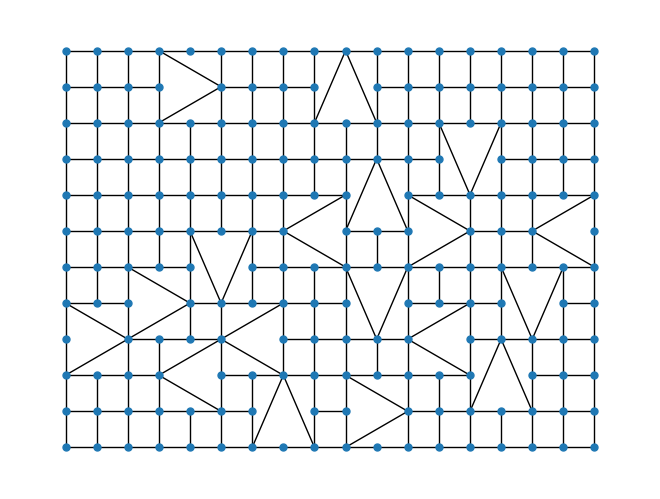

In [36]:
my_grid, pert_set = grid_candidates(18,12)
pert_18_12 = grid_perturbed(my_grid, pert_set)
is_planar, embedding = nx.check_planarity(pert_18_12)
nx.draw(pert_18_12, node_size=25, pos = {v:v for v in my_grid})

With our next function, we put everything together (literally), glueing together the 6 faces.

In [37]:
def box_grid_perturbed(m,n,p, threshold = 0.3):
    side1, centers1 = grid_candidates(m,n, threshold = threshold)
    side2, centers2 = grid_candidates(n,p, threshold = threshold)
    side3, centers3 = grid_candidates(m,p, threshold = threshold)
    side4, centers4 = grid_candidates(m,n, threshold = threshold)
    side5, centers5 = grid_candidates(n,p, threshold = threshold)
    side6, centers6 = grid_candidates(m,p, threshold = threshold)

    mapping1 = {(i,j): (i,j,0) for i,j in side1.nodes()}
    mapping2 = {(i,j): (0,i,j) for i,j in side2.nodes()}
    mapping3 = {(i,j): (i,0,j) for i,j in side3.nodes()}
    mapping4 = {(i,j): (i,j,p-1) for i,j in side4.nodes()}
    mapping5 = {(i,j): (m-1,i,j) for i,j in side5.nodes()}
    mapping6 = {(i,j): (i,n-1,j) for i,j in side6.nodes()}

    centers_3d = []

    for centers, mapping in [(centers1, mapping1), (centers2, mapping2), (centers3, mapping3), 
                            (centers4, mapping4), (centers5, mapping5), (centers6, mapping6)]:
        accepted = []
        for center in centers.copy():
            conflicts = any(sum(abs(a-b) for a,b in zip(old_center,mapping[center])) < 3 for old_center in centers_3d)
            if not conflicts:
                accepted.append(center)
                centers_3d.append(mapping[center])
        centers[:] = accepted

    for side, centers in [(side1, centers1), (side2, centers2), (side3, centers3), 
                          (side4, centers4), (side5, centers5), (side6, centers6)]:
        grid_perturbed(side, centers) 

    sides = []
    for side, mapping in [[side1, mapping1],[side2, mapping2],[side3, mapping3],
                          [side4, mapping4],[side5, mapping5],[side6, mapping6]]:
        sides.append(nx.relabel_nodes(side, mapping).copy())
        
    G_box = nx.compose_all([sides[0], sides[1], sides[2], sides[3], sides[4], sides[5]])
    return G_box

As an example, here is ```box_grid_perturbed(3,4,5,0)```; the 0 means that we don't make any perturbations, so the graph is easier to identify.

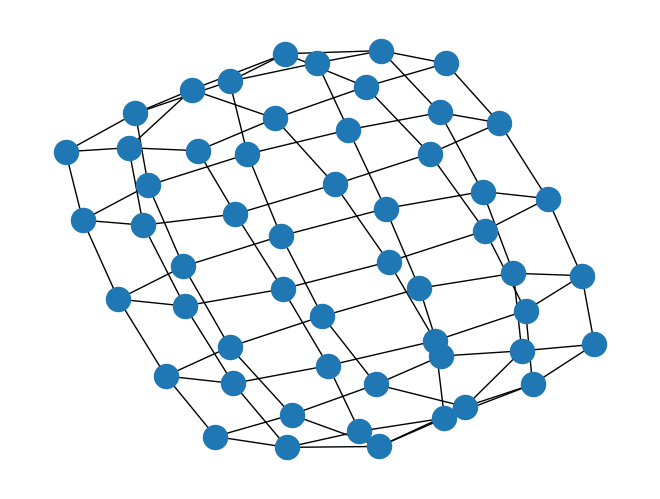

In [38]:
small_box = box_grid_perturbed(3,4,5,0)
nx.draw(small_box, pos = nx.spring_layout(small_box, seed=13))

And here are a few of the promised larger examples (roughly 12,500 vertices each). <br> Note that finding the vertex order actually takes more time than ```G_random_rseq```, which is what we time.

In [42]:
for i in range(10):
    medium_box = box_grid_perturbed(40,50,60)
    G = medium_box
    is_planar, embedding = nx.check_planarity(medium_box)
    assert is_planar
    cnts = {deg:0 for deg in range(8)} 
    for vertex, deg in list(medium_box.degree()):
        cnts[deg] += 1
    order = find_order_for_7lists(G, check=False)
    G_random_lists = make_lists(G, 7, 7) 
    coloring1 = build_random_coloring(G, G_random_lists, G_order = order)
    coloring2 = build_random_coloring(G, G_random_lists, G_order = order)
    t = perf_counter()
    G_random_rseq = find_rseq_treap(G, coloring1, coloring2, G_random_lists, order, info=True)
    print(f"Graph {i} has degree counts is {cnts} and took time {perf_counter()-t:.6f}s")


Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 13917}
Graph 0 has degree counts is {0: 0, 1: 0, 2: 0, 3: 3941, 4: 5133, 5: 3183, 6: 375, 7: 0} and took time 0.099203s
Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 13791}
Graph 1 has degree counts is {0: 0, 1: 0, 2: 0, 3: 3978, 4: 5053, 5: 3182, 6: 394, 7: 0} and took time 0.106144s
Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 13860}
Graph 2 has degree counts is {0: 0, 1: 0, 2: 0, 3: 3956, 4: 5081, 5: 3188, 6: 380, 7: 0} and took time 0.099885s
Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 13917}
Graph 3 has degree counts is {0: 0, 1: 0, 2: 0, 3: 4007, 4: 5009, 5: 3209, 6: 395, 7: 0} and took time 0.097914s
Recoloring sequence is valid.
{'max_times': 3, 'min_times': 0, 'total_times': 13854}
Graph 4 has degree counts is {0: 0, 1: 0, 2: 0, 3: 3950, 4: 5148, 5: 3098, 6: 422, 7: 0} and took time 0.201226s
Recoloring